# Seaborn solutions: Seaborn

Worked solutions to the exercises. Other correct answers are possible; what matters is that the result is right and the code is readable.

## Exercise 1

Load the `penguins` dataset. Draw a histogram of `bill_depth_mm` coloured by species, and describe what you see.

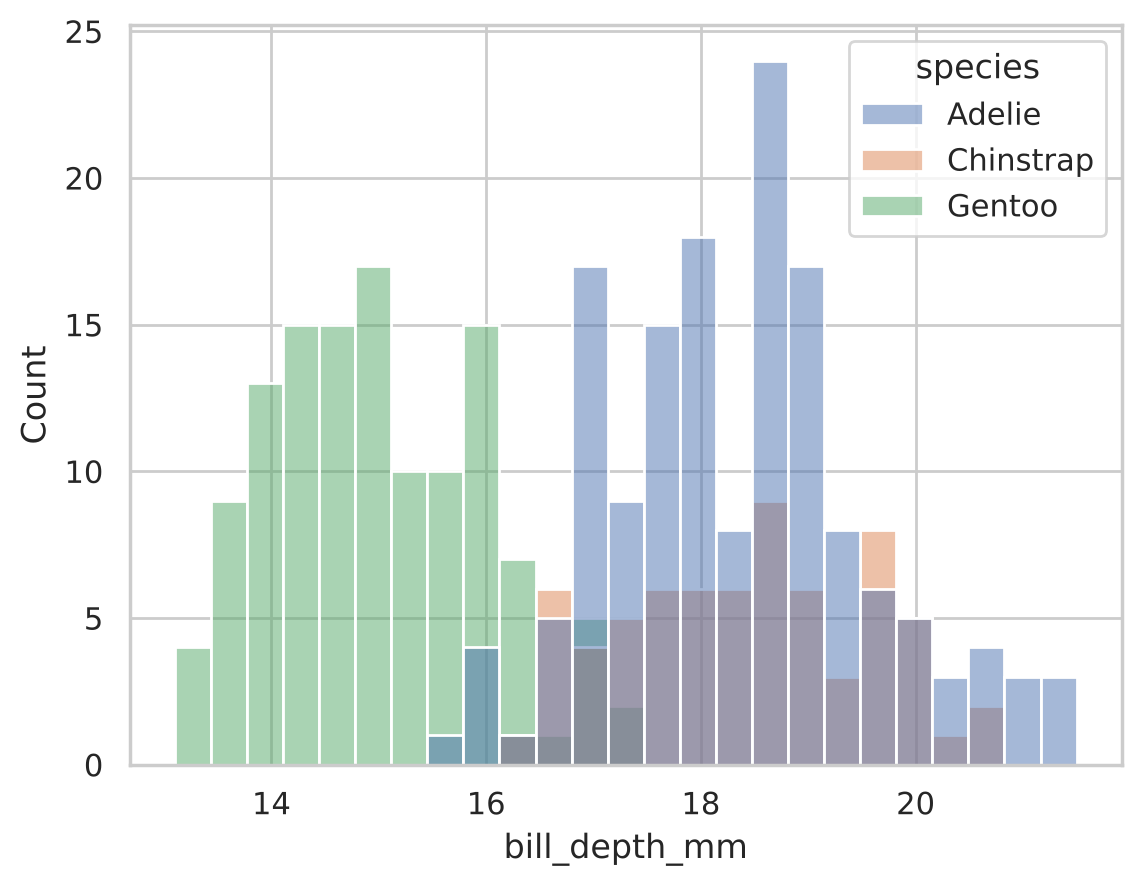

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
penguins = sns.load_dataset("penguins")
sns.histplot(data=penguins, x="bill_depth_mm", hue="species", bins=25, alpha=0.5)
plt.show()

Gentoo penguins have clearly shallower bills; Adelie and Chinstrap overlap.

## Exercise 2

Compare the distribution of `body_mass_g` by species and sex with a violin plot, using `split=True`.

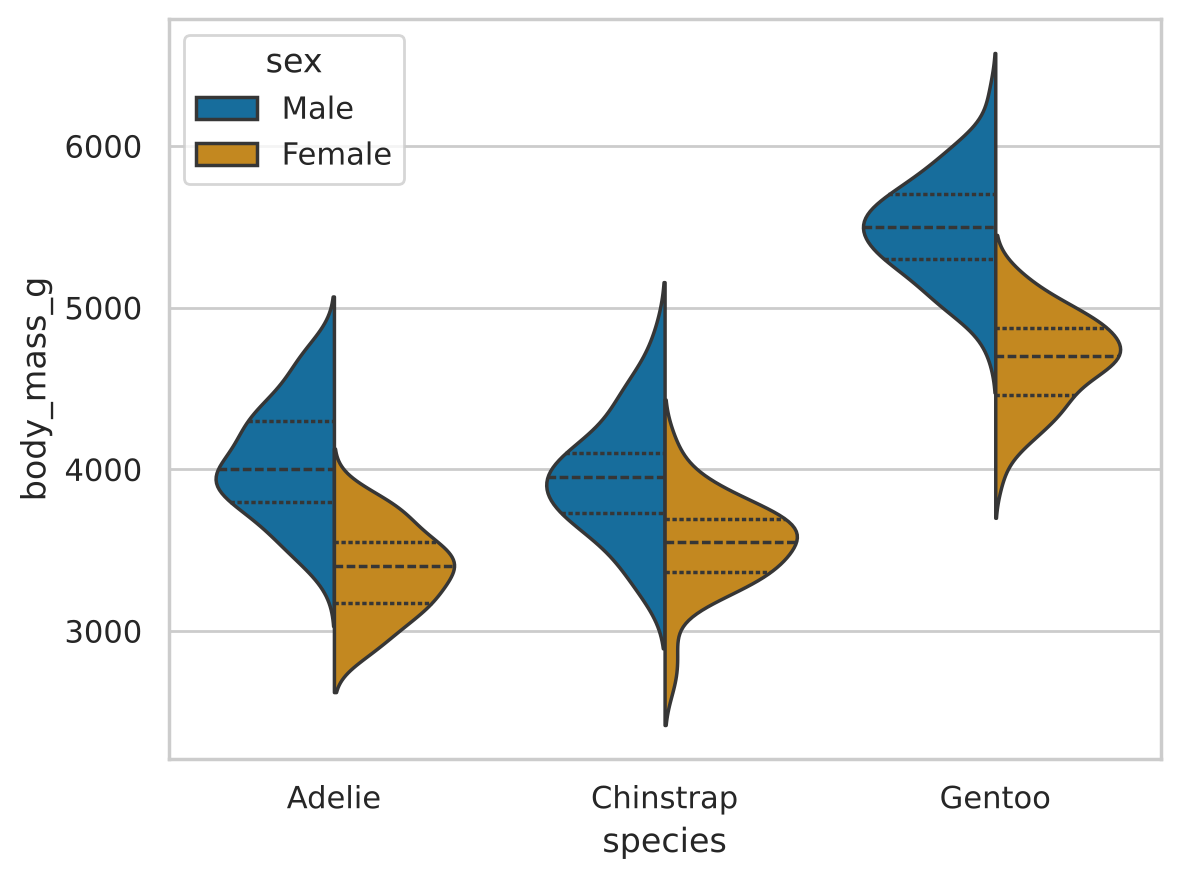

In [2]:
sns.violinplot(data=penguins, x="species", y="body_mass_g", hue="sex", split=True, inner="quart", palette="colorblind")
plt.show()

## Exercise 3

From `tips`, make a bar plot of the mean tip by day, with error bars showing the standard error. Order the days Thur, Fri, Sat, Sun.

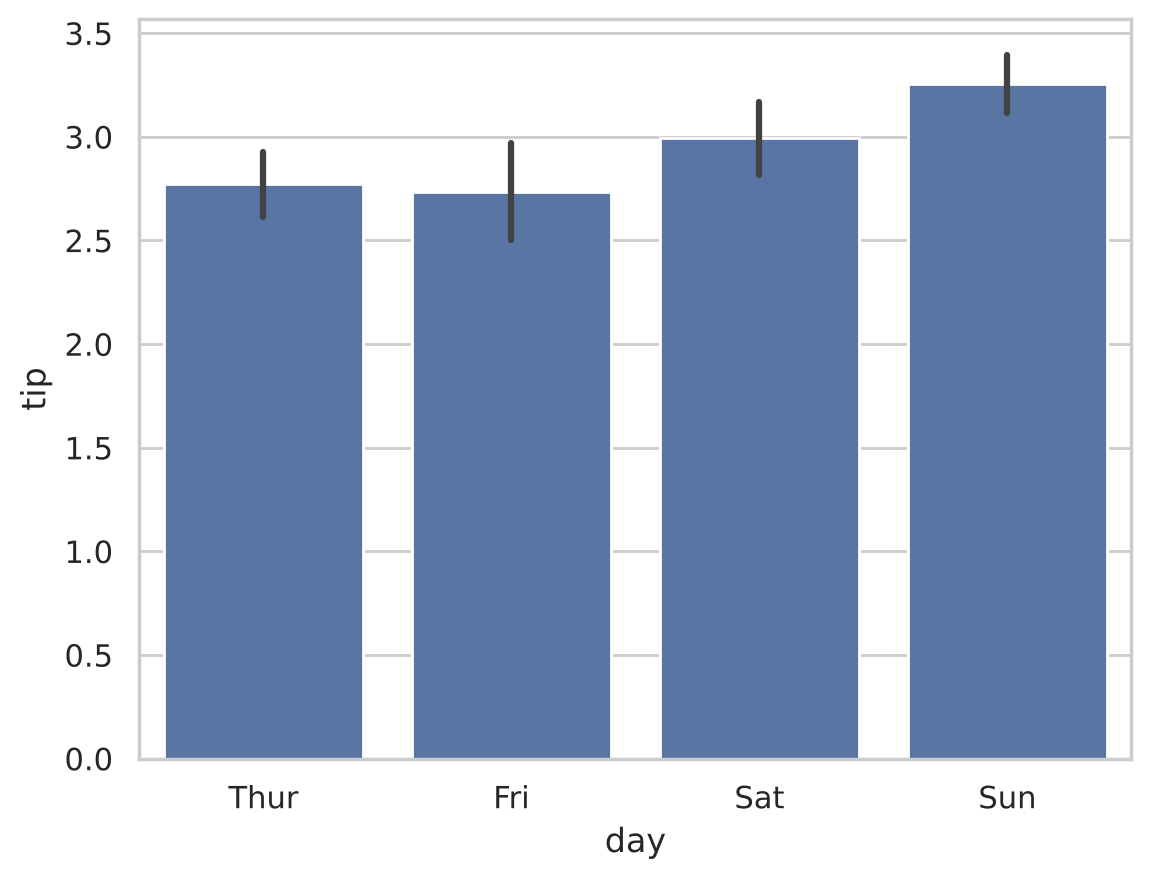

In [3]:
tips = sns.load_dataset("tips")
sns.barplot(data=tips, x="day", y="tip", errorbar="se", order=["Thur", "Fri", "Sat", "Sun"])
plt.show()

## Exercise 4

Draw a box plot of `total_bill` by day with the individual bills shown as a strip plot on top.

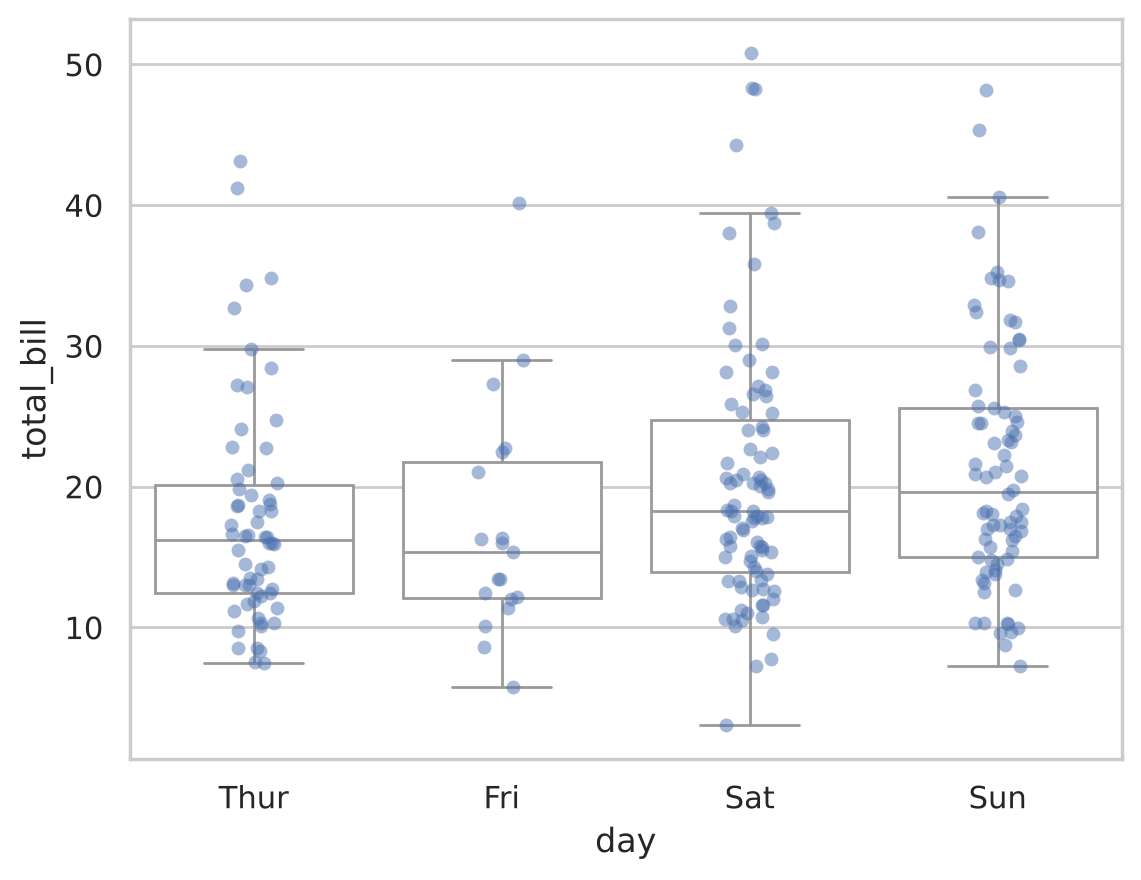

In [4]:
ax = sns.boxplot(data=tips, x="day", y="total_bill", color="white", showfliers=False)
sns.stripplot(data=tips, x="day", y="total_bill", alpha=0.5, ax=ax)
plt.show()

## Exercise 5

Fit a regression line of `tip` on `total_bill` separately for lunch and dinner with `lmplot`. Do the slopes look different?

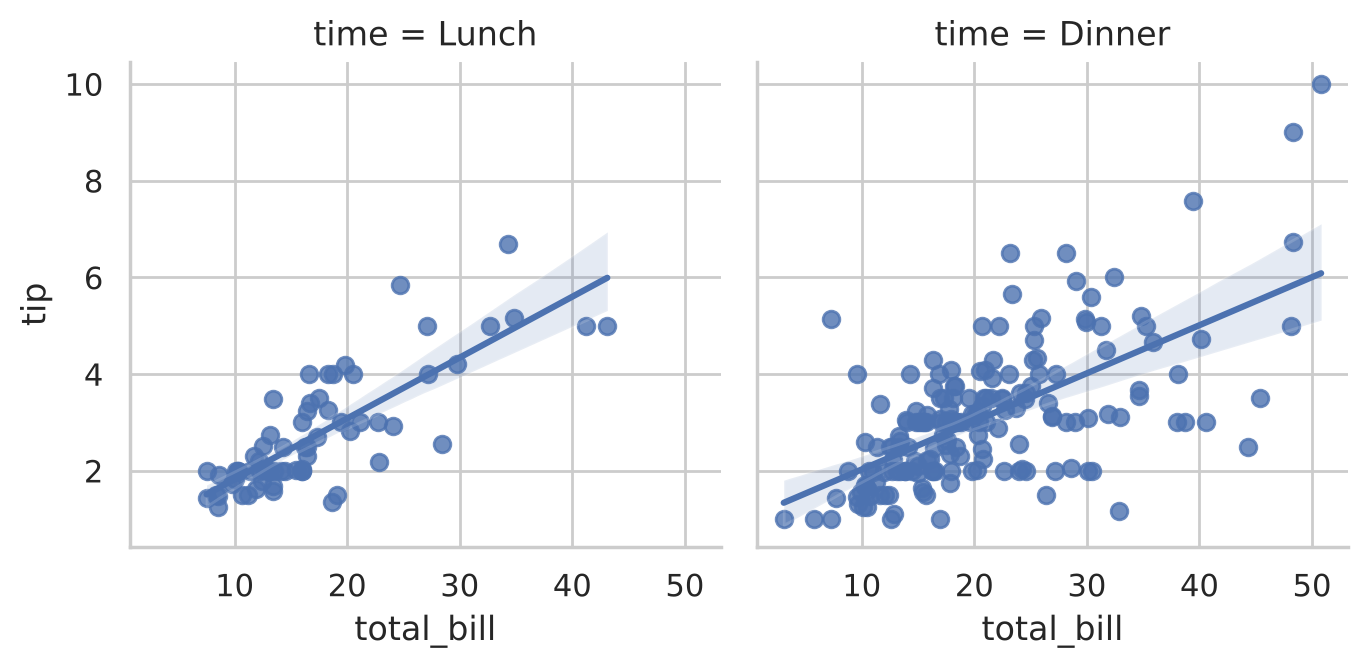

Lunch 0.126
Dinner 0.099


In [5]:
sns.lmplot(data=tips, x="total_bill", y="tip", col="time", height=3.5)
plt.show()
for t, g in tips.groupby("time", observed=True):
    print(t, round(np.polyfit(g["total_bill"], g["tip"], 1)[0], 3))

## Exercise 6

Load `../../datasets/raw/lab_results.csv` and plot mean glucose by visit as a line with its 95% confidence band.

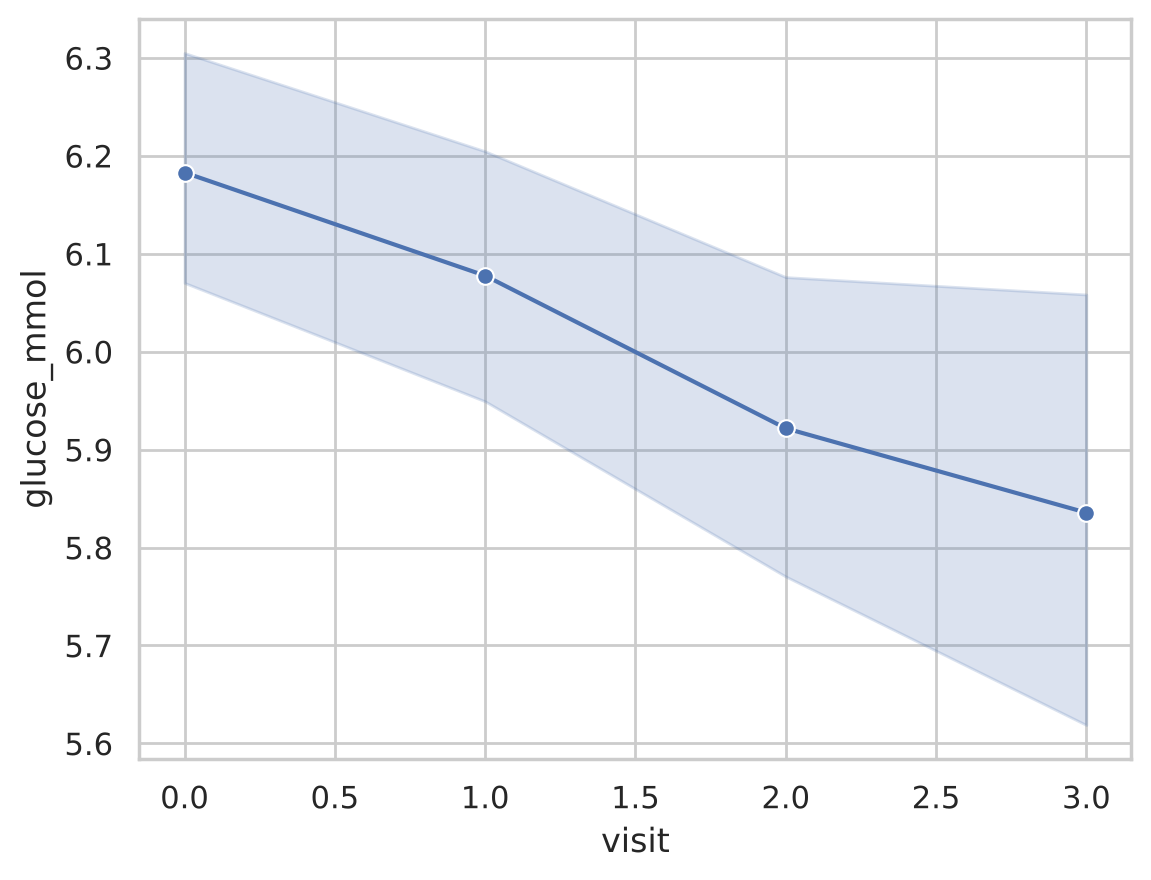

In [6]:
labs = pd.read_csv("../../datasets/raw/lab_results.csv")
sns.lineplot(data=labs, x="visit", y="glucose_mmol", marker="o")
plt.show()

## Exercise 7

Make a correlation heatmap of the four numeric lab columns (glucose, haemoglobin, systolic and diastolic BP) with a diverging palette centred at zero and annotated values.

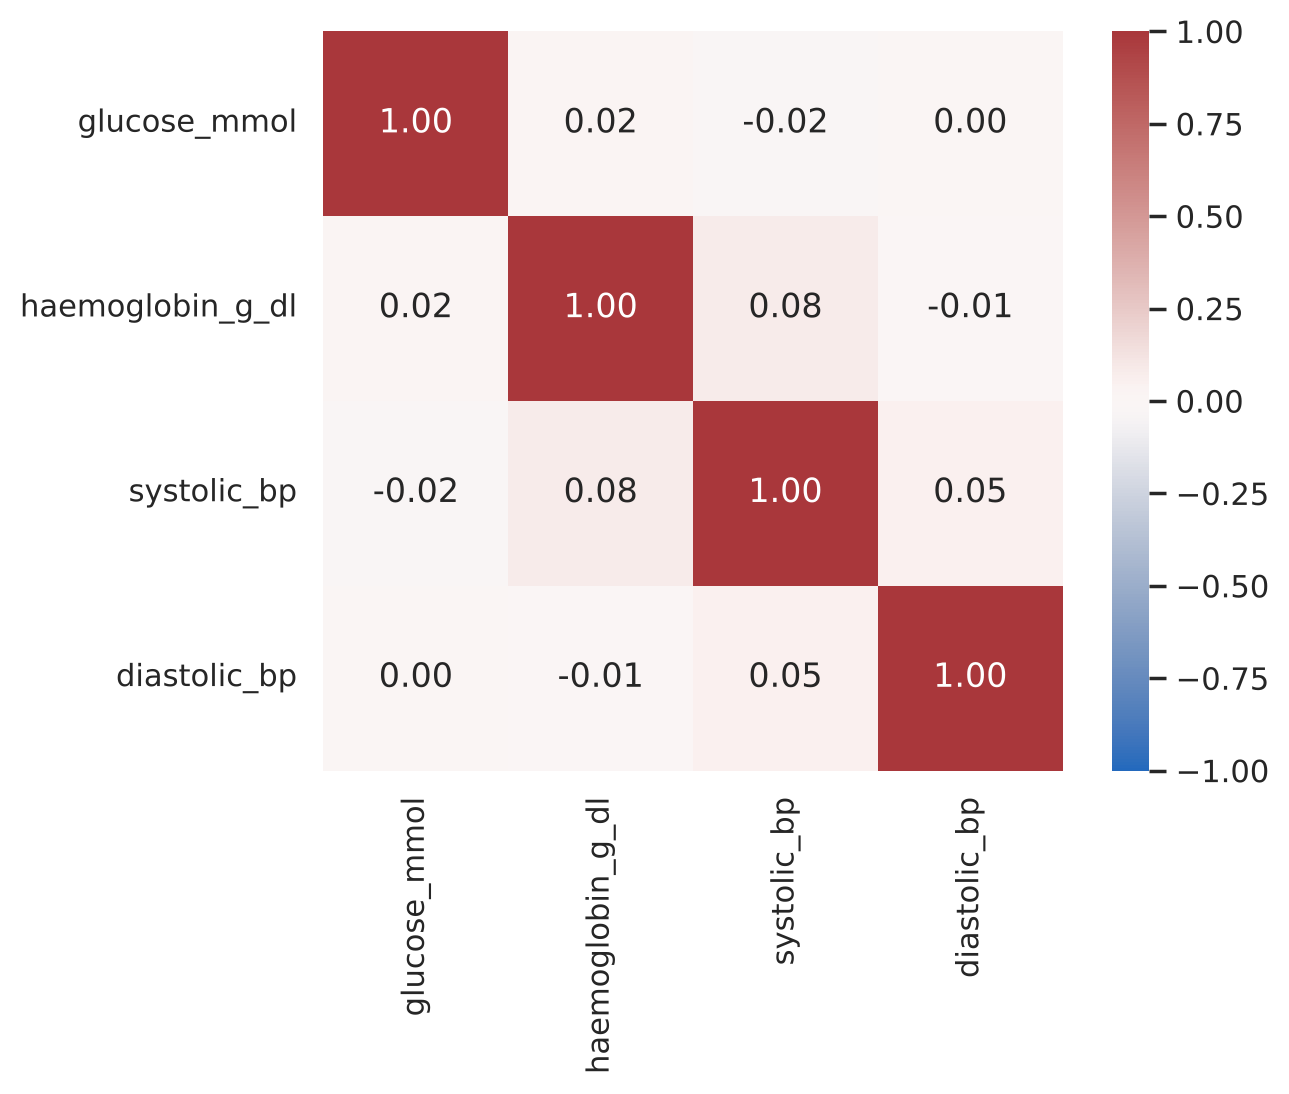

In [7]:
c = labs[["glucose_mmol", "haemoglobin_g_dl", "systolic_bp", "diastolic_bp"]].corr()
sns.heatmap(c, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True)
plt.show()

## Exercise 8

Draw a `pairplot` of the penguins' four measurements coloured by species, using `corner=True`. Which pair of measurements separates the three species best?

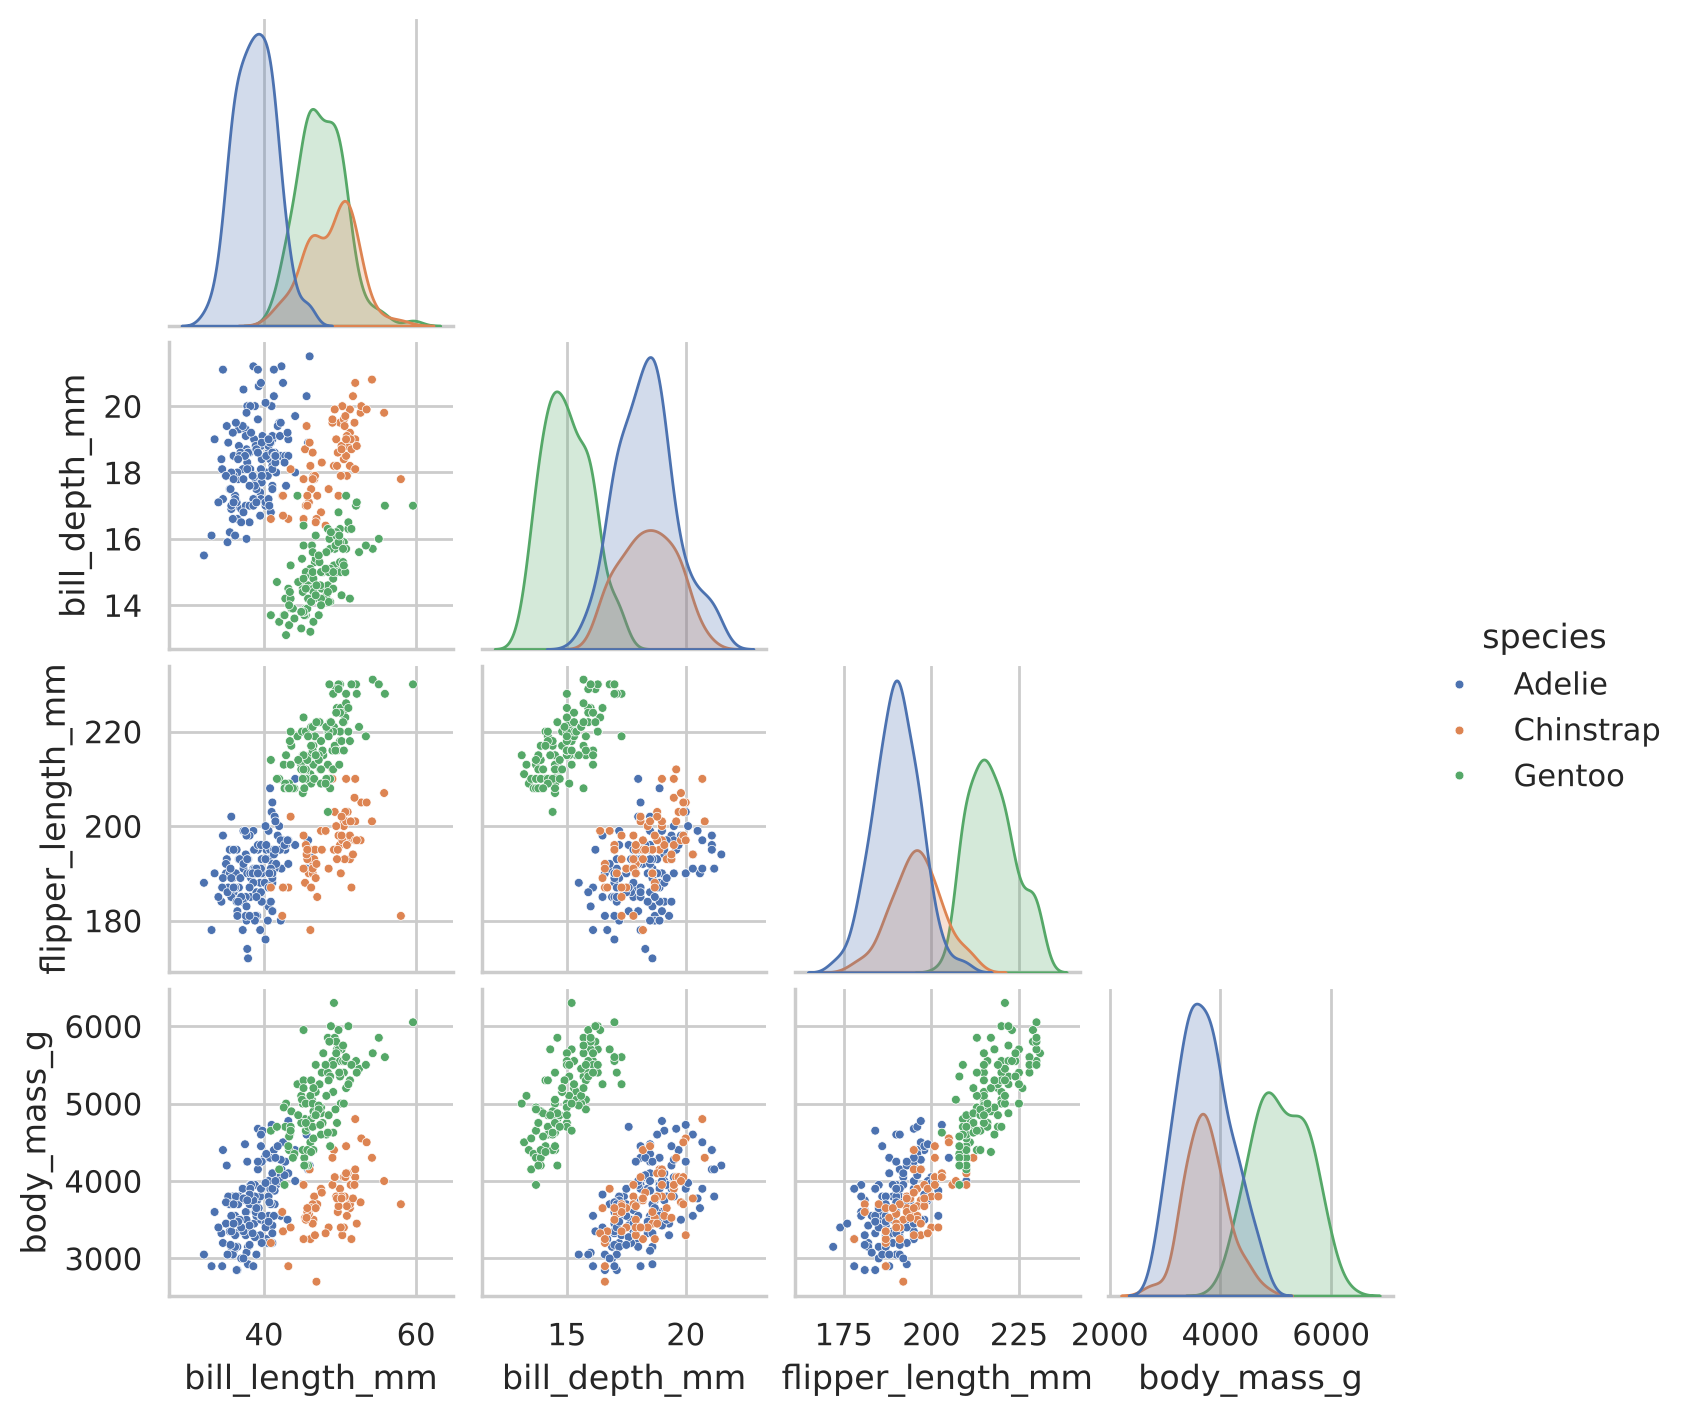

In [8]:
sns.pairplot(penguins.dropna(), hue="species", corner=True, height=1.8, plot_kws={"s": 10})
plt.show()

Bill length against bill depth (or bill length against flipper length) separates all three species fairly cleanly.

## Exercise 9

Use `FacetGrid` to draw a histogram of `tip` for every combination of `sex` (columns) and `smoker` (rows).

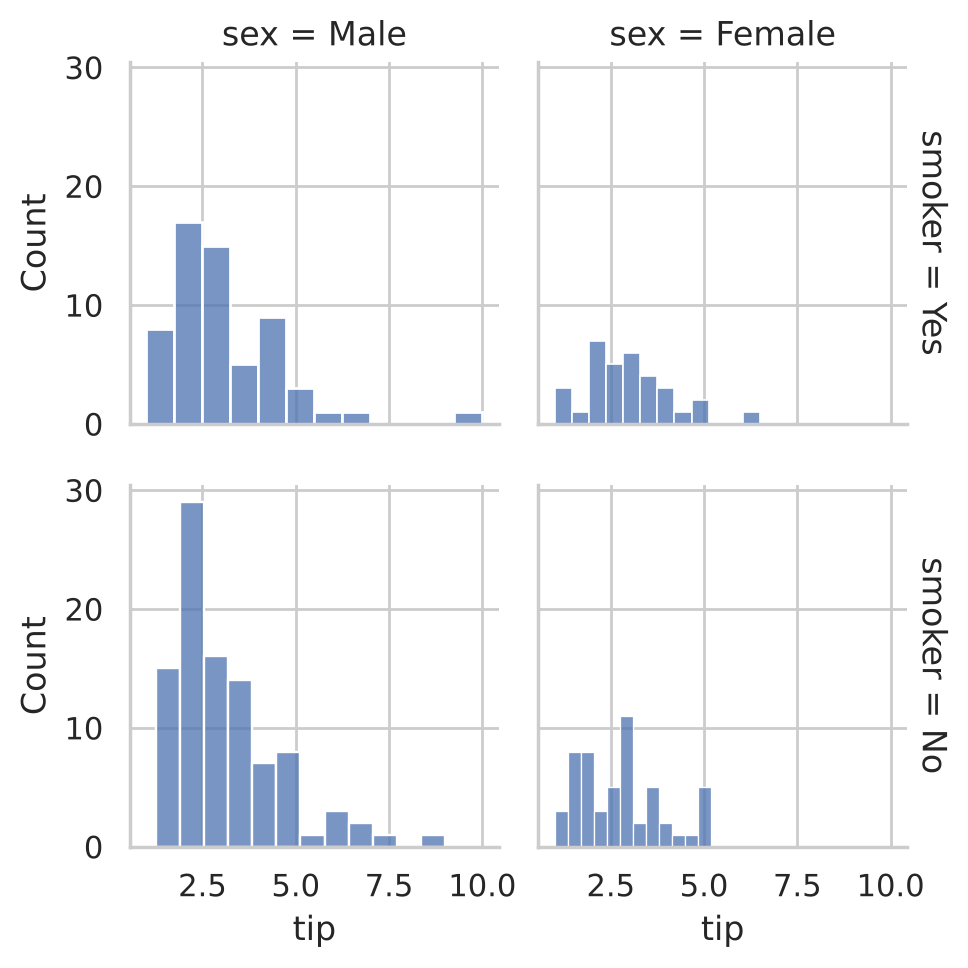

In [9]:
g = sns.FacetGrid(tips, col="sex", row="smoker", height=2.5, margin_titles=True)
g.map_dataframe(sns.histplot, x="tip", bins=12)
plt.show()

## Exercise 10

Make a two-panel figure 7 inches wide, in the `paper` context, suitable for a report: panel A, a box plot of flipper length by species; panel B, a scatter of flipper length against body mass. Label the panels A and B, give units, and save it as a 300 dpi PNG (then delete the file).

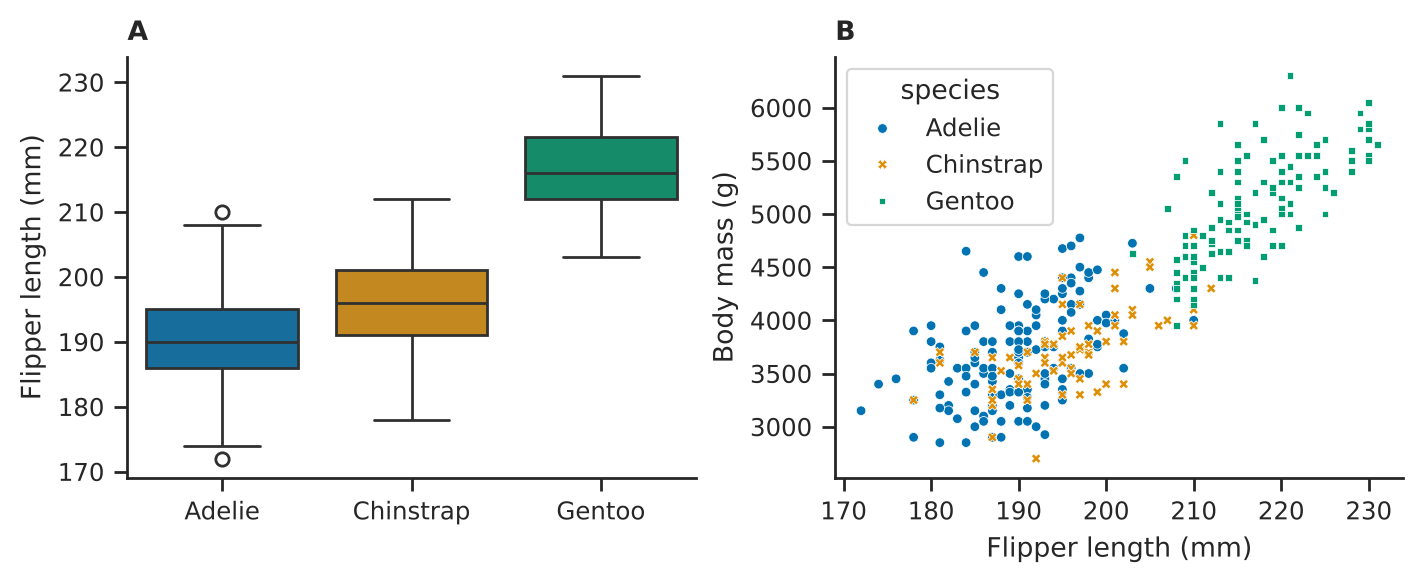

In [10]:
import os
sns.set_theme(style="ticks", context="paper")
p = penguins.dropna()
fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), layout="constrained")
sns.boxplot(data=p, x="species", y="flipper_length_mm", hue="species", palette="colorblind", ax=axes[0])
axes[0].set(xlabel="", ylabel="Flipper length (mm)"); axes[0].set_title("A", loc="left", fontweight="bold")
sns.scatterplot(data=p, x="flipper_length_mm", y="body_mass_g", hue="species", style="species", palette="colorblind", s=12, ax=axes[1])
axes[1].set(xlabel="Flipper length (mm)", ylabel="Body mass (g)"); axes[1].set_title("B", loc="left", fontweight="bold")
sns.despine(fig)
fig.savefig("exercise_figure.png", dpi=300)
plt.show()
os.remove("exercise_figure.png")
sns.set_theme()